In [37]:
# File and folder handling
import os

# Deep learning framework
import tensorflow as tf
from tensorflow import keras

# Data visualization
import matplotlib.pyplot as plt

# Model architectures
from tensorflow.keras import Sequential, Model

# Neural network layers
from tensorflow.keras.layers import Dense, Flatten, GlobalAveragePooling2D

# Pretrained CNN models
from tensorflow.keras.applications import VGG16, VGG19

# Image loading and preprocessing
from tensorflow.keras.preprocessing import image

from tqdm.auto import tqdm
import numpy as np


In [3]:
# Dataset directory
data_dir = r"D:\LLM-Fine-Tuning\Fine-tuning-CNN-Models\hymenoptera_data"

# Dataset splits and classes
splits = ["train", "val"]
classes = ["ants", "bees"]

# Count images in each folder
for split in splits:
    print(f"\n{split.upper()} DATASET")
    total = 0

    for cls in classes:
        folder = os.path.join(data_dir, split, cls)
        images = [f for f in os.listdir(folder)
                  if f.lower().endswith((".jpg", ".jpeg", ".png"))]

        print(f"{cls}: {len(images)} images")
        total += len(images)

    print(f"Total: {total} images")


TRAIN DATASET
ants: 123 images
bees: 121 images
Total: 244 images

VAL DATASET
ants: 70 images
bees: 83 images
Total: 153 images


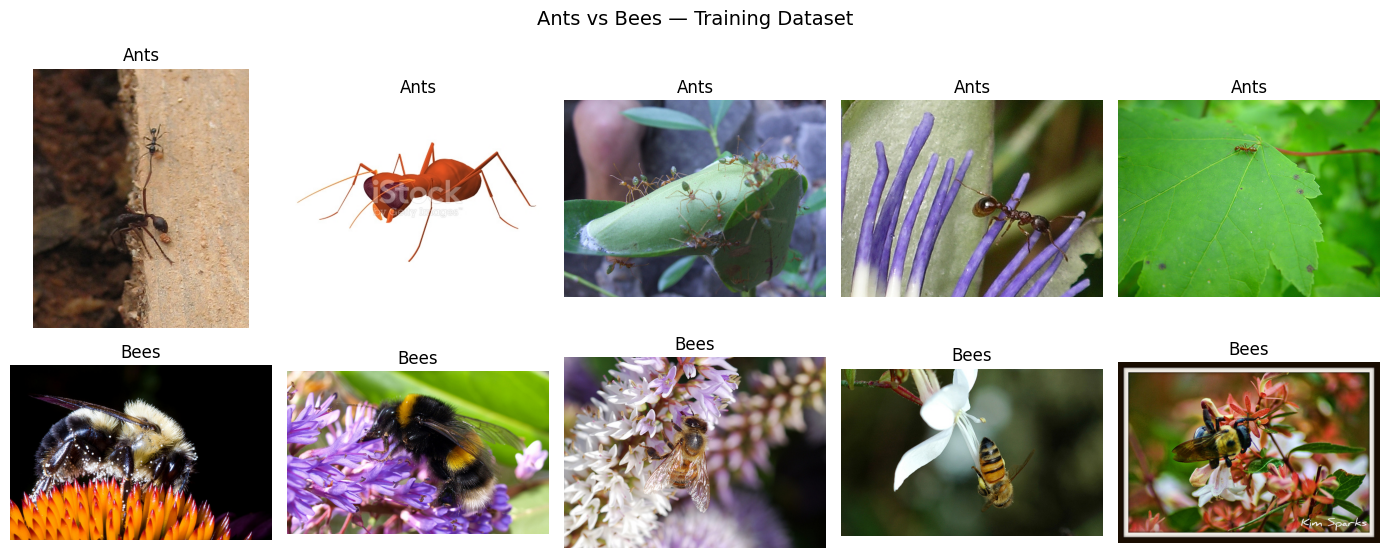

In [5]:
import random
from PIL import Image

# Display 5 random images from each class
fig, axes = plt.subplots(2, 5, figsize=(14, 6))

for row, cls in enumerate(classes):
    folder = os.path.join(data_dir, "train", cls)
    images = [f for f in os.listdir(folder)
              if f.lower().endswith((".jpg", ".jpeg", ".png"))]

    # Randomly select 5 images
    samples = random.sample(images, min(5, len(images)))

    for col, filename in enumerate(samples):
        img = Image.open(os.path.join(folder, filename)).convert("RGB")

        axes[row, col].imshow(img)
        axes[row, col].set_title(cls.capitalize())
        axes[row, col].axis("off")

plt.suptitle("Ants vs Bees — Training Dataset", fontsize=14)
plt.tight_layout()
plt.show()

## **`Type 1: Full Fine-Tuning (VGG16)`**

In this approach, all pretrained VGG16 layers are unfrozen and trained on the Ants vs Bees dataset.

- **Pretrained Model:** VGG16 (ImageNet)
- **Method:** Full Fine-Tuning
- **Trainable Parameters:** 138.36 Million
- **Classification:** Ants vs Bees (2 Classes)
- **Learning Rate:** 0.00001
- **Optimizer:** RMSprop

**Next Experiment:** Type 2 – Partial Fine-Tuning

### **VGG16 architecture diagram**

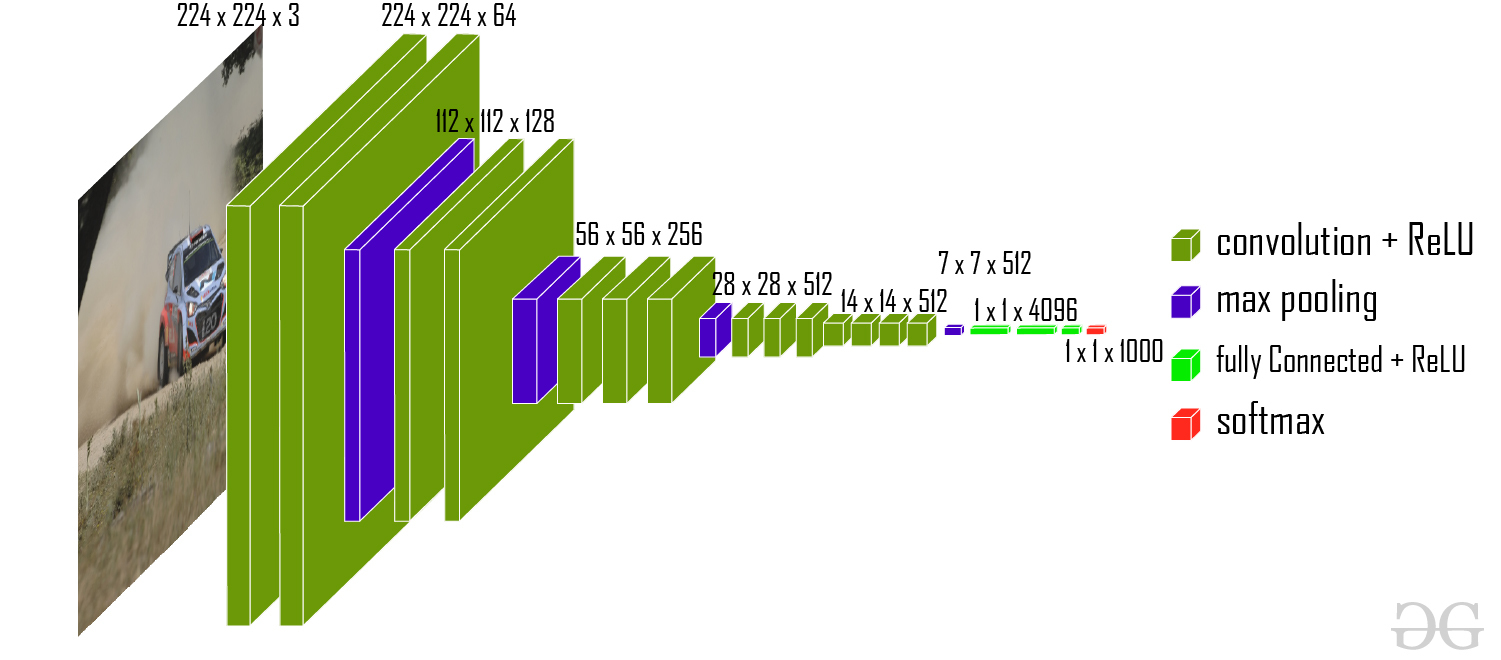

In [13]:
# Load the pretrained VGG16 model
vgg16_model = VGG16(
    weights="imagenet",
    include_top=True,
    input_shape=(224, 224, 3)
)

# Display model architecture
vgg16_model.summary()

553467096/553467096 ━━━━━━━━━━━━━━━━━━━━ 98s 0us/step


Model: "vgg16"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_4 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv1 (Conv2D)           │ (None, 224, 224, 64)   │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv2 (Conv2D)           │ (None, 224, 224, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool (MaxPooling2D)      │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv1 (Conv2D)           │ (None, 112, 112, 128)  │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv2 (Conv2D)           │ (None, 112, 112, 128)  │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pool (MaxPooling2D)      │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv1 (Conv2D)           │ (None, 56, 56, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv2 (Conv2D)           │ (None, 56, 56, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv3 (Conv2D)           │ (None, 56, 56, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_pool (MaxPooling2D)      │ (None, 28, 28, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv1 (Conv2D)           │ (None, 28, 28, 512)    │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv2 (Conv2D)           │ (None, 28, 28, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv3 (Conv2D)           │ (None, 28, 28, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_pool (MaxPooling2D)      │ (None, 14, 14, 512)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv1 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv2 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv3 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_pool (MaxPooling2D)      │ (None, 7, 7, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ fc1 (Dense)                     │ (None, 4096)           │   102,764,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ fc2 (Dense)                     │ (None, 4096)           │    16,781,312 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ predictions (Dense)             │ (None, 1000)           │     4,097,000 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 138,357,544 (527.79 MB)

 Trainable params: 138,357,544 (527.79 MB)

 Non-trainable params: 0 (0.00 B)

In [14]:
print(f"Total Parameters: {vgg16_model.count_params() / 1e6:.2f} Million")

Total Parameters: 138.36 Million


In [16]:
model = Sequential()
model.add(vgg16_model)
model.add(Dense(2, activation="sigmoid"))

In [20]:
# Load training images
train_ds = keras.utils.image_dataset_from_directory(
    directory=r"D:\LLM-Fine-Tuning\Fine-tuning-CNN-Models\hymenoptera_data\train",
    labels="inferred",
    label_mode="int",
    batch_size=16,
    image_size=(224, 224)
)

# Load validation images
validation_ds = keras.utils.image_dataset_from_directory(
    directory=r"D:\LLM-Fine-Tuning\Fine-tuning-CNN-Models\hymenoptera_data\val",
    labels="inferred",
    label_mode="int",
    batch_size=16,
    image_size=(224, 224)
)

Found 245 files belonging to 2 classes.
Found 153 files belonging to 2 classes.


In [21]:
print("Classes:", train_ds.class_names)
print("Training Batches:", len(train_ds))
print("Validation Batches:", len(validation_ds))

Classes: ['ants', 'bees']
Training Batches: 16
Validation Batches: 10


In [22]:
from tensorflow.keras.applications.vgg16 import preprocess_input

# Preprocess images for pretrained VGG16
def process(image, label):
    image = tf.cast(image, tf.float32)
    image = preprocess_input(image)
    return image, label

# Apply preprocessing to both datasets
train_ds = train_ds.map(process)
validation_ds = validation_ds.map(process)

In [23]:
from tensorflow.keras.optimizers import RMSprop

# Configure the model for training
model.compile(
    optimizer=RMSprop(learning_rate=1e-5),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [24]:
from tensorflow.keras.callbacks import EarlyStopping

# Stop training if validation loss does not improve for 2 epochs
early_stop = EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True,
    verbose=1
)

# Train the model with early stopping
history = model.fit(
    train_ds,
    epochs=20,
    validation_data=validation_ds,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 36s 2s/step - accuracy: 0.6000 - loss: 0.6837 - val_accuracy: 0.7190 - val_loss: 0.6790
Epoch 2/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 38s 2s/step - accuracy: 0.8367 - loss: 0.6707 - val_accuracy: 0.8562 - val_loss: 0.6740
Epoch 3/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 38s 2s/step - accuracy: 0.9551 - loss: 0.6633 - val_accuracy: 0.8693 - val_loss: 0.6689
Epoch 4/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 41s 2s/step - accuracy: 0.9796 - loss: 0.6587 - val_accuracy: 0.8889 - val_loss: 0.6660
Epoch 5/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 39s 2s/step - accuracy: 0.9796 - loss: 0.6569 - val_accuracy: 0.8954 - val_loss: 0.6637
Epoch 6/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 37s 2s/step - accuracy: 0.9878 - loss: 0.6546 - val_accuracy: 0.8824 - val_loss: 0.6638
Epoch 7/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 45s 3s/step - accuracy: 0.9755 - loss: 0.6534 - val_accuracy: 0.8627 - val_loss: 0.6620
Epoch 8/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 48s 3s/step - accuracy: 0.9837 - loss: 0.6510 - val_accuracy: 0.8497 - val_loss:

In [26]:
# Check best validation performance
print(f"Best Validation Accuracy: {max(history.history['val_accuracy'])*100:.2f}%")
print(f"Lowest Validation Loss: {min(history.history['val_loss']):.4f}")

Best Validation Accuracy: 91.50%
Lowest Validation Loss: 0.6528


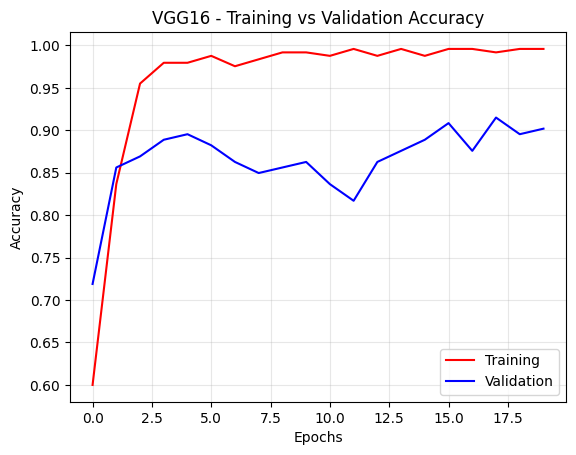

In [25]:
# Plot training and validation accuracy
plt.plot(history.history["accuracy"], color="red", label="Training")
plt.plot(history.history["val_accuracy"], color="blue", label="Validation")

# Add chart labels
plt.title("VGG16 - Training vs Validation Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

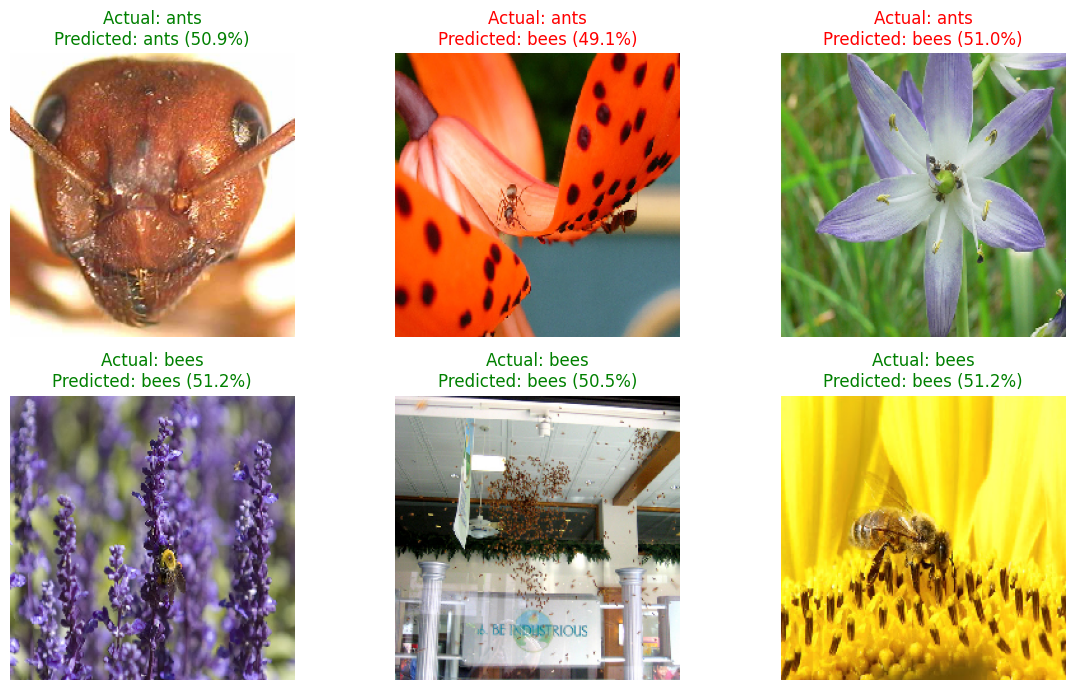

In [32]:
# Dataset path and class names
val_path = r"D:\LLM-Fine-Tuning\Fine-tuning-CNN-Models\hymenoptera_data\val"
classes = ["ants", "bees"]

# Select 3 random images from each class
fig, axes = plt.subplots(2, 3, figsize=(12, 7))

for row, cls in enumerate(classes):
    folder = os.path.join(val_path, cls)
    images = random.sample(os.listdir(folder), 3)

    for col, filename in enumerate(images):
        # Load and resize image
        img = tf.keras.utils.load_img(
            os.path.join(folder, filename),
            target_size=(224, 224)
        )

        # Preprocess image for VGG16
        x = tf.keras.utils.img_to_array(img)
        x = preprocess_input(np.expand_dims(x, axis=0))

        # Predict class and confidence
        probs = model.predict(x, verbose=0)[0]
        pred = classes[np.argmax(probs)]
        confidence = np.max(probs) * 100

        # Display prediction
        axes[row, col].imshow(img)
        axes[row, col].set_title(
            f"Actual: {cls}\nPredicted: {pred} ({confidence:.1f}%)",
            color="green" if pred == cls else "red"
        )
        axes[row, col].axis("off")

plt.tight_layout()
plt.show()

In [34]:
# Check trainable layers inside VGG16
for layer in vgg16_model.layers:
    print(layer.name, layer.trainable)

input_layer_4 True
block1_conv1 True
block1_conv2 True
block1_pool True
block2_conv1 True
block2_conv2 True
block2_pool True
block3_conv1 True
block3_conv2 True
block3_conv3 True
block3_pool True
block4_conv1 True
block4_conv2 True
block4_conv3 True
block4_pool True
block5_conv1 True
block5_conv2 True
block5_conv3 True
block5_pool True
flatten True
fc1 True
fc2 True
predictions True


In [35]:
# Count trainable and non-trainable parameters
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ vgg16 (Functional)              │ (None, 1000)           │   138,357,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 2)              │         2,002 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 276,719,094 (1.03 GB)

 Trainable params: 138,359,546 (527.80 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 138,359,548 (527.80 MB)

## **`Type 2: Partial Fine-Tuning (VGG16)`**

In this approach, the early layers of the pretrained VGG16 model are frozen, while the last convolutional block (Block 5) and the new classification layer are trained.

- **Pretrained Model:** VGG16 (ImageNet)
- **Method:** Partial Fine-Tuning
- **Frozen Layers:** Blocks 1–4
- **Trainable Layers:** Block 5 + Classification Head
- **Classification:** Ants vs Bees (2 Classes)
- **Learning Rate:** 0.00001
- **Optimizer:** RMSprop

**Goal:** Compare Partial Fine-Tuning with Full Fine-Tuning using training accuracy, validation accuracy, and loss.

In [41]:
# Load pretrained VGG16 without classification layers
vgg_conv_base = VGG16(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

# Freeze Blocks 1–4 and unfreeze Block 5
for layer in vgg_conv_base.layers:
    layer.trainable = layer.name.startswith("block5_")

# Build the classification model
model = Sequential([
    vgg_conv_base,
    Flatten(),
    Dense(256, activation="relu"),
    Dense(2, activation="softmax")
])

# Compile the model
model.compile(
    optimizer=RMSprop(learning_rate=1e-5),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# Display model architecture
model.summary()

Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ vgg16 (Functional)              │ (None, 7, 7, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 256)            │     6,422,784 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 2)              │           514 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 21,137,986 (80.64 MB)

 Trainable params: 13,502,722 (51.51 MB)

 Non-trainable params: 7,635,264 (29.13 MB)

In [42]:


# Stop training if validation loss does not improve for 2 epochs
early_stop = EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True,
    verbose=1
)

# Train the model and validate after each epoch
partial_history = model.fit(
    train_ds,
    epochs=20,
    validation_data=validation_ds,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 13s 792ms/step - accuracy: 0.6735 - loss: 4.0513 - val_accuracy: 0.7190 - val_loss: 2.1196
Epoch 2/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 13s 798ms/step - accuracy: 0.9796 - loss: 0.0691 - val_accuracy: 0.7451 - val_loss: 1.9433
Epoch 3/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 13s 841ms/step - accuracy: 1.0000 - loss: 0.0046 - val_accuracy: 0.7516 - val_loss: 1.9345
Epoch 4/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 15s 973ms/step - accuracy: 1.0000 - loss: 6.8667e-04 - val_accuracy: 0.7516 - val_loss: 1.9254
Epoch 5/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 14s 871ms/step - accuracy: 1.0000 - loss: 3.7992e-04 - val_accuracy: 0.7516 - val_loss: 1.9151
Epoch 6/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 14s 873ms/step - accuracy: 1.0000 - loss: 1.9657e-04 - val_accuracy: 0.7451 - val_loss: 1.9016
Epoch 7/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 14s 872ms/step - accuracy: 1.0000 - loss: 9.5550e-05 - val_accuracy: 0.7582 - val_loss: 1.8896
Epoch 8/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 14s 878ms/step - accuracy: 1.0000 - loss: 4


### Interpretation — VGG16 Partial Fine-Tuning

The VGG16 model was trained using partial fine-tuning, where Blocks 1–4 were frozen and Block 5 and the classification layers were trainable.

**Results (Epoch 20):**
- **Training Accuracy:** 100%
- **Validation Accuracy:** 77.78%
- **Training Loss:** 0.0000027
- **Validation Loss:** 1.8026

**Interpretation:**

The model achieved perfect training accuracy but showed lower performance on validation data. The large gap between training and validation accuracy (22.22%) indicates **overfitting**. The model learned the training images extremely well but struggled to generalize to unseen images.

**Conclusion:**

Partial fine-tuning resulted in overfitting. Techniques such as data augmentation, dropout, and Global Average Pooling may help improve generalization.
